In [1]:
!pip install -q tensorflow kagglehub matplotlib seaborn scikit-learn pillow

In [2]:
import kagglehub

# Download the Food-101 dataset
path = kagglehub.dataset_download("dansbecker/food-101")

print("Dataset downloaded successfully!")
print("Dataset path:", path)

Using Colab cache for faster access to the 'food-101' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/food-101


In [3]:
import os

dataset_path = "/kaggle/input/food-101"

print("Dataset path exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("\nFiles and folders:")
    print(os.listdir(dataset_path))
else:
    print("\nDataset not found at this path.")
    print("Please check the dataset download location.")

Dataset path exists: True

Files and folders:
['food-101.zip', 'food-101']


In [4]:
import os

dataset_path = "/kaggle/input/food-101"

for root, dirs, files in os.walk(dataset_path):
    if "images" in dirs:
        print("Image directory:", os.path.join(root, "images"))
        break

Image directory: /kaggle/input/food-101/food-101/__MACOSX/food-101/images


In [7]:
import os

base_path = "/kaggle/input/food-101"

# Check likely image directories directly
paths = [
    os.path.join(base_path, "food-101", "images"),
    os.path.join(base_path, "food-101", "food-101", "images"),
    os.path.join(base_path, "food-101", "__MACOSX", "food-101", "images"),
]

for path in paths:
    if os.path.isdir(path):
        print("\nChecking:", path)
        print("First 10 items:", os.listdir(path)[:10])


Checking: /kaggle/input/food-101/food-101/food-101/images
First 10 items: ['macarons', 'french_toast', 'lobster_bisque', 'prime_rib', 'pork_chop', 'guacamole', 'baby_back_ribs', 'mussels', 'beef_carpaccio', 'poutine']

Checking: /kaggle/input/food-101/food-101/__MACOSX/food-101/images
First 10 items: ['macarons', 'french_toast', '._prime_rib', '._grilled_salmon', 'lobster_bisque', '._sushi', '._waffles', '._filet_mignon', 'prime_rib', 'pork_chop']


Total food categories: 101

First 10 categories: ['macarons', 'french_toast', 'lobster_bisque', 'prime_rib', 'pork_chop', 'guacamole', 'baby_back_ribs', 'mussels', 'beef_carpaccio', 'poutine']


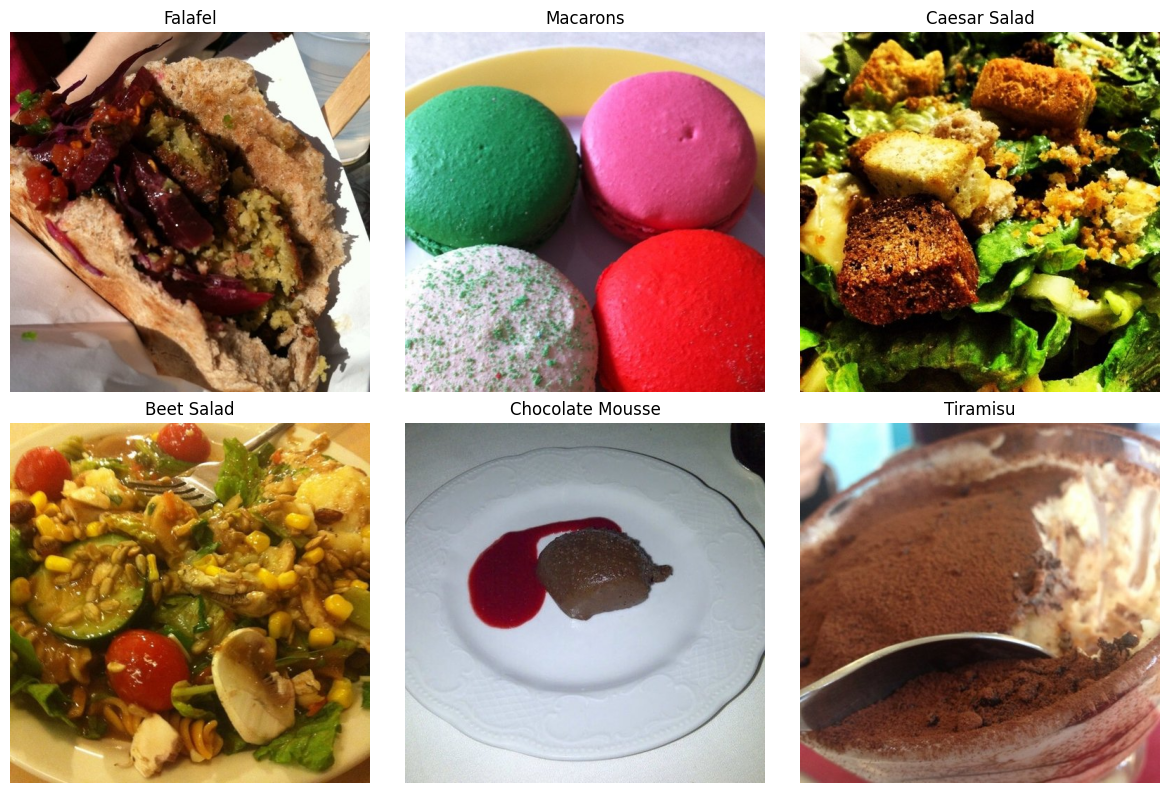

In [8]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Correct dataset path
dataset_path = "/kaggle/input/food-101/food-101/food-101/images"

# Get food categories
categories = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
    and not folder.startswith("._")
    and not folder.startswith("__")
]

print("Total food categories:", len(categories))
print("\nFirst 10 categories:", categories[:10])

# Select 6 random categories
selected_categories = random.sample(categories, 6)

# Display sample images
plt.figure(figsize=(12, 8))

for i, category in enumerate(selected_categories):
    category_path = os.path.join(dataset_path, category)

    images = [
        file for file in os.listdir(category_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
        and not file.startswith("._")
    ]

    if not images:
        continue

    image_path = os.path.join(
        category_path, random.choice(images)
    )

    image = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(category.replace("_", " ").title())
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Dataset path
dataset_path = "/kaggle/input/food-101/food-101/food-101/images"

# Select 5 food categories
selected_categories = [
    "pizza",
    "hamburger",
    "sushi",
    "ice_cream",
    "french_fries"
]

# Image parameters
IMG_SIZE = 128
BATCH_SIZE = 32

print("TensorFlow version:", tf.__version__)
print("Dataset path exists:", os.path.exists(dataset_path))
print("Selected categories:", selected_categories)

TensorFlow version: 2.21.0
Dataset path exists: True
Selected categories: ['pizza', 'hamburger', 'sushi', 'ice_cream', 'french_fries']


In [10]:
for category in selected_categories:
    category_path = os.path.join(dataset_path, category)

    if os.path.isdir(category_path):
        images = [
            f for f in os.listdir(category_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
            and not f.startswith("._")
        ]

        print(f"{category}: {len(images)} images")
    else:
        print(f"{category}: NOT FOUND")

pizza: 1000 images
hamburger: 1000 images
sushi: 1000 images
ice_cream: 1000 images
french_fries: 1000 images


In [11]:
import tensorflow as tf
import os

# Dataset path
dataset_path = "/kaggle/input/food-101/food-101/food-101/images"

# Selected food categories
selected_categories = [
    "pizza",
    "hamburger",
    "sushi",
    "ice_cream",
    "french_fries"
]

IMG_SIZE = 128
BATCH_SIZE = 32
SEED = 42

# Load training dataset (80%)
train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    labels="inferred",
    label_mode="int",
    class_names=selected_categories,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

# Load validation dataset (20%)
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    labels="inferred",
    label_mode="int",
    class_names=selected_categories,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("\nDataset loaded successfully!")
print("Food categories:", train_dataset.class_names)

Found 5000 files belonging to 5 classes.
Using 4000 files for training.
Found 5000 files belonging to 5 classes.
Using 1000 files for validation.

Dataset loaded successfully!
Food categories: ['pizza', 'hamburger', 'sushi', 'ice_cream', 'french_fries']


In [12]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

print("Training and validation datasets are ready!")

Training and validation datasets are ready!


In [14]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Build CNN model
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Normalize pixel values
    layers.Rescaling(1./255),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(5, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model created successfully!")

CNN model created successfully!


In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Training configuration
EPOCHS = 10

# Train the model
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 28s 154ms/step - accuracy: 0.2565 - loss: 1.5720 - val_accuracy: 0.3470 - val_loss: 1.4640
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.3658 - loss: 1.4650 - val_accuracy: 0.3530 - val_loss: 1.4283
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - accuracy: 0.4275 - loss: 1.3841 - val_accuracy: 0.4210 - val_loss: 1.3709
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - accuracy: 0.4810 - loss: 1.2927 - val_accuracy: 0.4710 - val_loss: 1.2902
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.5368 - loss: 1.1932 - val_accuracy: 0.4660 - val_loss: 1.2683
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/step - accuracy: 0.5922 - loss: 1.0491 - val_accuracy: 0.5350 - val_loss: 1.2310
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - accuracy: 0.6605 - loss: 0.8992 - val_accuracy: 0.5580 - val_loss: 1.1460
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.7168 - loss: 0.7584 - val_ac

In [17]:
# Training configuration
EPOCHS = 10

# Train the model
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 71ms/step - accuracy: 0.8435 - loss: 0.4306 - val_accuracy: 0.5500 - val_loss: 1.5999
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.8652 - loss: 0.3517 - val_accuracy: 0.5510 - val_loss: 1.6351
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.8742 - loss: 0.3344 - val_accuracy: 0.5330 - val_loss: 1.7676
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.9007 - loss: 0.2889 - val_accuracy: 0.5770 - val_loss: 1.7527
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.9155 - loss: 0.2393 - val_accuracy: 0.5670 - val_loss: 1.8044
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.9233 - loss: 0.2159 - val_accuracy: 0.5810 - val_loss: 2.0350
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.9310 - loss: 0.1836 - val_accuracy: 0.5250 - val_loss: 2.5134
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.9335 - loss: 0.1823 - val_accu

In [19]:
import numpy as np
from sklearn.metrics import classification_report

# Define the food category names
class_names = [
    "pizza",
    "hamburger",
    "sushi",
    "ice_cream",
    "french_fries"
]

# Get actual labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in validation_dataset
])

# Generate predictions
predictions = model.predict(validation_dataset)

# Convert probabilities to predicted class indices
y_pred = np.argmax(predictions, axis=1)

# Display classification report
print("CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step
CLASSIFICATION REPORT
              precision    recall  f1-score   support

       pizza       0.18      0.22      0.20       189
   hamburger       0.21      0.18      0.19       191
       sushi       0.25      0.17      0.20       213
   ice_cream       0.22      0.23      0.22       204
french_fries       0.21      0.25      0.23       203

    accuracy                           0.21      1000
   macro avg       0.21      0.21      0.21      1000
weighted avg       0.21      0.21      0.21      1000



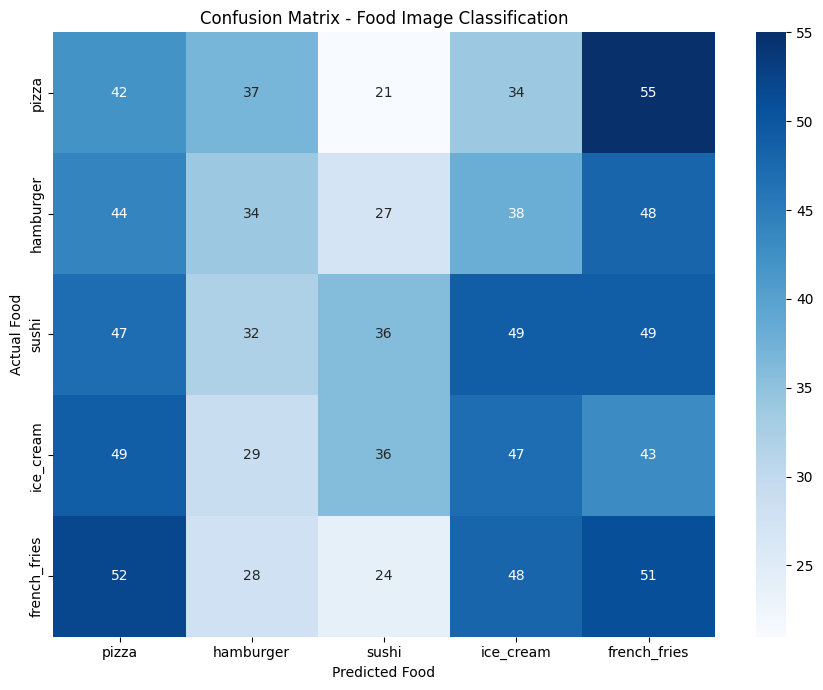

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Food Image Classification")
plt.xlabel("Predicted Food")
plt.ylabel("Actual Food")
plt.tight_layout()
plt.show()

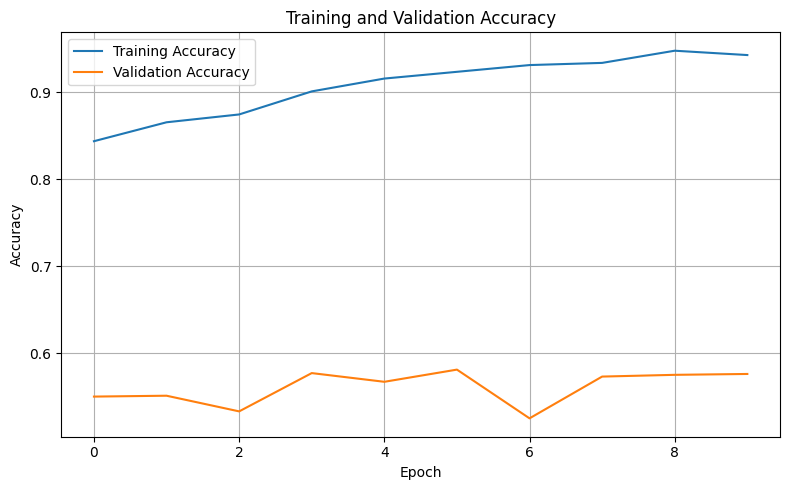

In [21]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

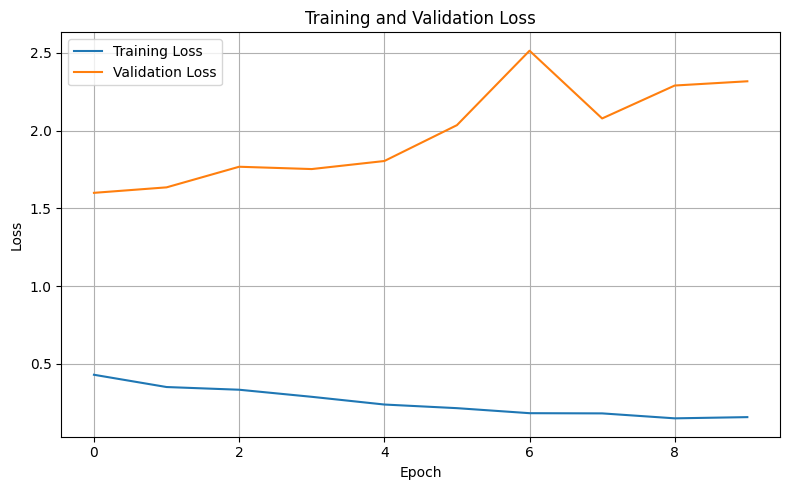

In [22]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

# Calorie estimates per typical serving
calorie_info = {
    "pizza": {
        "calories": 285,
        "serving": "1 medium slice (approx. 100 g)"
    },
    "hamburger": {
        "calories": 295,
        "serving": "1 standard burger (approx. 100 g)"
    },
    "sushi": {
        "calories": 150,
        "serving": "Approx. 100 g"
    },
    "ice_cream": {
        "calories": 207,
        "serving": "Approx. 100 g"
    },
    "french_fries": {
        "calories": 312,
        "serving": "Approx. 100 g"
    }
}

def predict_food(image_path):
    # Load and resize image
    image = Image.open(image_path).convert("RGB")
    resized_image = image.resize((128, 128))

    # Convert image to NumPy array
    image_array = np.array(resized_image)
    image_array = np.expand_dims(image_array, axis=0)

    # Predict food category
    predictions = model.predict(image_array, verbose=0)

    predicted_index = np.argmax(predictions[0])
    predicted_food = class_names[predicted_index]
    confidence = predictions[0][predicted_index] * 100

    # Retrieve estimated calories
    info = calorie_info[predicted_food]

    # Display uploaded image
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Predicted Food: {predicted_food.replace('_', ' ').title()}")
    plt.show()

    print("=" * 40)
    print("FOOD IMAGE RECOGNITION RESULTS")
    print("=" * 40)
    print(f"Predicted Food: {predicted_food.replace('_', ' ').title()}")
    print(f"Prediction Confidence: {confidence:.2f}%")
    print(f"Estimated Calories: {info['calories']} kcal")
    print(f"Reference Serving: {info['serving']}")
    print("=" * 40)

    print("\nNote: Calories are approximate reference values.")
    print("Actual calories depend on portion size and ingredients.")

Saving french fries.jpg to french fries.jpg
Saving ice cream.jpg to ice cream.jpg
Saving sushi.jpg to sushi.jpg
Saving hamburger.jpg to hamburger.jpg
Saving pizza.jpg to pizza.jpg


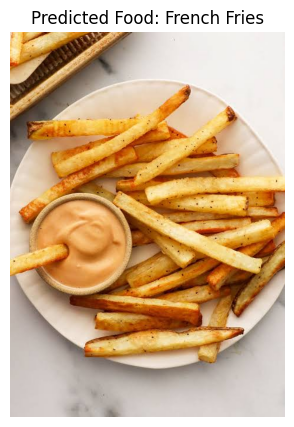

FOOD IMAGE RECOGNITION RESULTS
Predicted Food: French Fries
Prediction Confidence: 99.92%
Estimated Calories: 312 kcal
Reference Serving: Approx. 100 g

Note: Calories are approximate reference values.
Actual calories depend on portion size and ingredients.


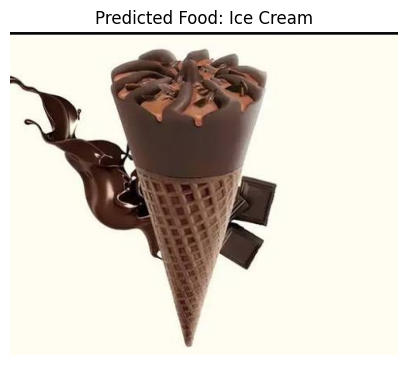

FOOD IMAGE RECOGNITION RESULTS
Predicted Food: Ice Cream
Prediction Confidence: 99.97%
Estimated Calories: 207 kcal
Reference Serving: Approx. 100 g

Note: Calories are approximate reference values.
Actual calories depend on portion size and ingredients.


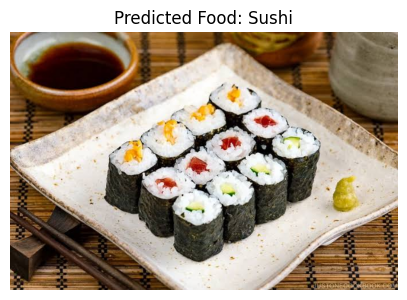

FOOD IMAGE RECOGNITION RESULTS
Predicted Food: Sushi
Prediction Confidence: 96.87%
Estimated Calories: 150 kcal
Reference Serving: Approx. 100 g

Note: Calories are approximate reference values.
Actual calories depend on portion size and ingredients.


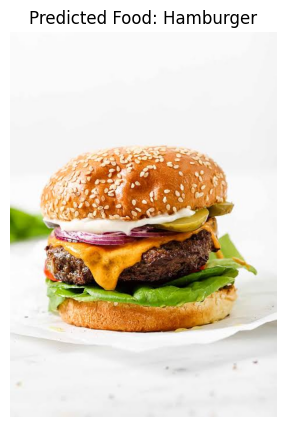

FOOD IMAGE RECOGNITION RESULTS
Predicted Food: Hamburger
Prediction Confidence: 100.00%
Estimated Calories: 295 kcal
Reference Serving: 1 standard burger (approx. 100 g)

Note: Calories are approximate reference values.
Actual calories depend on portion size and ingredients.


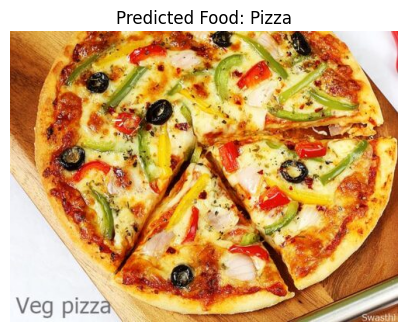

FOOD IMAGE RECOGNITION RESULTS
Predicted Food: Pizza
Prediction Confidence: 100.00%
Estimated Calories: 285 kcal
Reference Serving: 1 medium slice (approx. 100 g)

Note: Calories are approximate reference values.
Actual calories depend on portion size and ingredients.


In [24]:
uploaded = files.upload()

for filename in uploaded.keys():
    predict_food(filename)


In [25]:
# Save the trained model
model.save("food_recognition_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [30]:
from google.colab import files

files.download("food_recognition_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import json

class_names = [
    "pizza",
    "hamburger",
    "sushi",
    "ice_cream",
    "french_fries"
]

with open("food_classes.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Class names saved successfully!")

Class names saved successfully!


In [29]:
files.download("food_classes.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>